Laptop Prices PROJECT

* Introduction & Setup

In [2]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt
File=r"C:\Users\saifa\Downloads\laptop_price.csv"
from IPython.core.interactiveshell import InteractiveShell

InteractiveShell.ast_node_interactivity = "all"

ltp= pd.read_csv(File, encoding='latin1')
ltp


,laptop_ID,Company,Product,TypeName,Inches,ScreenResolution,Cpu,Ram,Memory,Gpu,OpSys,Weight,Price_euros
0,1,Apple,MacBook Pro,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 2.3GHz,8GB,128GB SSD,Intel Iris Plus Graphics 640,macOS,1.37kg,1339.69
1,2,Apple,Macbook Air,Ultrabook,13.3,1440x900,Intel Core i5 1.8GHz,8GB,128GB Flash Storage,Intel HD Graphics 6000,macOS,1.34kg,898.94
2,3,HP,250 G6,Notebook,15.6,Full HD 1920x1080,Intel Core i5 7200U 2.5GHz,8GB,256GB SSD,Intel HD Graphics 620,No OS,1.86kg,575.00
3,4,Apple,MacBook Pro,Ultrabook,15.4,IPS Panel Retina Display 2880x1800,Intel Core i7 2.7GHz,16GB,512GB SSD,AMD Radeon Pro 455,macOS,1.83kg,2537.45
4,5,Apple,MacBook Pro,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 3.1GHz,8GB,256GB SSD,Intel Iris Plus Graphics 650,macOS,1.37kg,1803.60
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1298,1316,Lenovo,Yoga 500-14ISK,2 in 1 Convertible,14.0,IPS Panel Full HD / Touchscreen 1920x1080,Intel Core i7 6500U 2.5GHz,4GB,128GB SSD,Intel HD Graphics 520,Windows 10,1.8kg,638.00
1299,1317,Lenovo,Yoga 900-13ISK,2 in 1 Convertible,13.3,IPS Panel Quad HD+ / Touchscreen 3200x1800,Intel Core i7 6500U 2.5GHz,16GB,512GB SSD,Intel HD Graphics 520,Windows 10,1.3kg,1499.00
1300,1318,Lenovo,IdeaPad 100S-14IBR,Notebook,14.0,1366x768,Intel Celeron Dual Core N3050 1.6GHz,2GB,64GB Flash Storage,Intel HD Graphics,Windows 10,1.5kg,229.00
1301,1319,HP,15-AC110nv (i7-6500U/6GB/1TB/Radeon,Notebook,15.6,1366x768,Intel Core i7 6500U 2.5GHz,6GB,1TB HDD,AMD Radeon R5 M330,Windows 10,2.19kg,764.00


* Data Loading & Overview

### 2. Data Loading & Overview

* **Dataset Dimensions:** The dataset contains **1303 rows** and **13 columns**, representing various laptop specifications and prices[span_0](start_span)[span_0](end_span).
* **Data Quality Check:** Using `.isnull().sum()`, we verified that there are **no missing or null values** in the dataset.
* **Duplicates Check:** Verified that there are no duplicate rows using `.duplicated().sum()`.

In [15]:
ltp.shape
ltp.head(5)
ltp.info()
ltp.isnull().sum()
ltp.duplicated().sum()

(1303, 13)

,laptop_ID,Company,Product,TypeName,Inches,ScreenResolution,Cpu,Ram,Memory,Gpu,OpSys,Weight,Price_euros
0,1,Apple,MacBook Pro,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 2.3GHz,8GB,128GB SSD,Intel Iris Plus Graphics 640,macOS,1.37kg,1339.69
1,2,Apple,Macbook Air,Ultrabook,13.3,1440x900,Intel Core i5 1.8GHz,8GB,128GB Flash Storage,Intel HD Graphics 6000,macOS,1.34kg,898.94
2,3,HP,250 G6,Notebook,15.6,Full HD 1920x1080,Intel Core i5 7200U 2.5GHz,8GB,256GB SSD,Intel HD Graphics 620,No OS,1.86kg,575.00
3,4,Apple,MacBook Pro,Ultrabook,15.4,IPS Panel Retina Display 2880x1800,Intel Core i7 2.7GHz,16GB,512GB SSD,AMD Radeon Pro 455,macOS,1.83kg,2537.45
4,5,Apple,MacBook Pro,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 3.1GHz,8GB,256GB SSD,Intel Iris Plus Graphics 650,macOS,1.37kg,1803.60


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1303 entries, 0 to 1302
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   laptop_ID         1303 non-null   int64  
 1   Company           1303 non-null   object 
 2   Product           1303 non-null   object 
 3   TypeName          1303 non-null   object 
 4   Inches            1303 non-null   float64
 5   ScreenResolution  1303 non-null   object 
 6   Cpu               1303 non-null   object 
 7   Ram               1303 non-null   object 
 8   Memory            1303 non-null   object 
 9   Gpu               1303 non-null   object 
 10  OpSys             1303 non-null   object 
 11  Weight            1303 non-null   object 
 12  Price_euros       1303 non-null   float64
dtypes: float64(2), int64(1), object(10)
memory usage: 132.5+ KB


laptop_ID           0
Company             0
Product             0
TypeName            0
Inches              0
ScreenResolution    0
Cpu                 0
Ram                 0
Memory              0
Gpu                 0
OpSys               0
Weight              0
Price_euros         0
dtype: int64

0

## 3. Data Cleaning & Preprocessing

In this section, we clean and prepare the dataset for analysis through two main tasks:
1. **Numeric Columns Cleaning:** Stripping unit strings (`GB` from `Ram` and `kg` from `Weight`) and converting them to numeric data types (`int` and `float`).
2. **Feature Engineering:** Creating a simplified `Cpu_Brand` column by extracting the core CPU family (e.g., Intel Core i7, AMD Ryzen 7) to make price grouping clearer and more meaningful.
3. **Categorical Standardization (Operating Systems):** Grouping and standardizing different OS versions (e.g., merging Windows 7, 10, and S into a unified `Windows` category, and Mac OS X into `macOS`) to reduce data fragmentation and improve analysis accuracy.

> **💡 Note:** Standardizing categorical values prevents duplicate categories and ensures accurate grouping during exploratory data analysis (EDA).

In [10]:
# 1. Clean Ram and Weight columns
ltp['Ram']=ltp['Ram'].str.replace('GB','').astype(int)
ltp['Weight']=ltp['Weight'].str.replace('kg','').astype(float)


In [21]:
# 2. Extract CPU Brand (first 3 words of CPU model)
ltp['Cpu_Brand']=ltp['Cpu'].str.split().str[0:3].str.join(' ')
# Display top CPU brands distribution
ltp['Cpu_Brand'].value_counts().head(15)


Cpu_Brand
Intel Core i7           527
Intel Core i5           423
Intel Core i3           136
Intel Celeron Dual       80
Intel Pentium Quad       27
Intel Core M             19
AMD A9-Series 9420       12
Intel Celeron Quad        8
AMD A6-Series 9220        8
AMD A12-Series 9720P      7
Intel Atom x5-Z8350       5
AMD A8-Series 7410        4
Intel Atom x5-Z8550       4
Intel Pentium Dual        3
AMD A9-Series 9410        3
Name: count, dtype: int64

In [8]:
# 3. Standarize Operating Systems column
ltp['OpSys']=ltp['OpSys'].str.replace('Mac OS X','macOS')
ltp['OpSys']=ltp['OpSys'].str.replace('Windows 7','Windows')
ltp['OpSys']=ltp['OpSys'].str.replace('Windows 10','Windows')
ltp['OpSys']=ltp['OpSys'].str.replace('Windows S','Windows')
# Preview the cleaned data and value counts
ltp.head(15)
ltp['OpSys'].value_counts()



,laptop_ID,Company,Product,TypeName,Inches,ScreenResolution,Cpu,Ram,Memory,Gpu,OpSys,Weight,Price_euros
0,1,Apple,MacBook Pro,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 2.3GHz,8GB,128GB SSD,Intel Iris Plus Graphics 640,macOS,1.37kg,1339.69
1,2,Apple,Macbook Air,Ultrabook,13.3,1440x900,Intel Core i5 1.8GHz,8GB,128GB Flash Storage,Intel HD Graphics 6000,macOS,1.34kg,898.94
2,3,HP,250 G6,Notebook,15.6,Full HD 1920x1080,Intel Core i5 7200U 2.5GHz,8GB,256GB SSD,Intel HD Graphics 620,No OS,1.86kg,575.00
3,4,Apple,MacBook Pro,Ultrabook,15.4,IPS Panel Retina Display 2880x1800,Intel Core i7 2.7GHz,16GB,512GB SSD,AMD Radeon Pro 455,macOS,1.83kg,2537.45
4,5,Apple,MacBook Pro,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 3.1GHz,8GB,256GB SSD,Intel Iris Plus Graphics 650,macOS,1.37kg,1803.60
5,6,Acer,Aspire 3,Notebook,15.6,1366x768,AMD A9-Series 9420 3GHz,4GB,500GB HDD,AMD Radeon R5,Windows,2.1kg,400.00
6,7,Apple,MacBook Pro,Ultrabook,15.4,IPS Panel Retina Display 2880x1800,Intel Core i7 2.2GHz,16GB,256GB Flash Storage,Intel Iris Pro Graphics,macOS,2.04kg,2139.97
7,8,Apple,Macbook Air,Ultrabook,13.3,1440x900,Intel Core i5 1.8GHz,8GB,256GB Flash Storage,Intel HD Graphics 6000,macOS,1.34kg,1158.70
8,9,Asus,ZenBook UX430UN,Ultrabook,14.0,Full HD 1920x1080,Intel Core i7 8550U 1.8GHz,16GB,512GB SSD,Nvidia GeForce MX150,Windows,1.3kg,1495.00
9,10,Acer,Swift 3,Ultrabook,14.0,IPS Panel Full HD 1920x1080,Intel Core i5 8250U 1.6GHz,8GB,256GB SSD,Intel UHD Graphics 620,Windows,1.6kg,770.00


OpSys
Windows      1125
No OS          66
Linux          62
Chrome OS      27
macOS          21
Android         2
Name: count, dtype: int64

## 4. Exploratory Data Analysis (EDA)

In this section, we analyze the relationships between different laptop specifications (such as Company, CPU Brand, and RAM) and their corresponding prices using grouping and aggregation methods (`groupby` and `mean`).

In [6]:
#Group by Company and calculate average price, sorted descending 

company_price=ltp.groupby('Company')['Price_euros'].mean().sort_values(ascending=False)
company_price

Company
Razer        3346.142857
LG           2099.000000
MSI          1728.908148
Google       1677.666667
Microsoft    1612.308333
Apple        1564.198571
Huawei       1424.000000
Samsung      1413.444444
Toshiba      1267.812500
Dell         1186.068990
Xiaomi       1133.462500
Asus         1104.169367
Lenovo       1086.384444
HP           1067.774854
Fujitsu       729.000000
Acer          626.775825
Chuwi         314.296667
Mediacom      295.000000
Vero          217.425000
Name: Price_euros, dtype: float64

In [12]:
# Group by CPU Brand and calculate average price, sorted descending

cpu_price=ltp.groupby('Cpu_Brand')['Price_euros'].mean().sort_values(ascending=False)
cpu_price

Cpu_Brand
Intel Xeon E3-1535M         4644.000000
Intel Xeon E3-1505M         2524.000000
AMD Ryzen 1600              1695.000000
AMD Ryzen 1700              1682.333333
Intel Core i7               1595.779108
Intel Core M                1324.231579
Intel Core i5               1015.015248
AMD FX 8800P                 999.000000
AMD FX 9830P                 699.000000
Samsung Cortex A72&A53       659.000000
AMD A12-Series 9720P         658.795714
AMD A9-Series A9-9420        649.500000
AMD A12-Series 9700P         629.000000
AMD A10-Series 9620P         617.005000
AMD A10-Series A10-9620P     571.950000
Intel Pentium Dual           565.300000
AMD A9-Series 9410           549.990000
Intel Core i3                541.625956
AMD A10-Series 9600P         534.000000
Intel Atom x5-Z8550          498.317500
AMD A6-Series A6-9220        462.395000
AMD A8-Series 7410           448.500000
AMD A9-Series 9420           445.824167
Intel Pentium Quad           421.122222
AMD A6-Series 9220           4

In [4]:
# Group by RAM size and calculate average price , sorted descending

Ram_price=ltp.groupby('Ram')['Price_euros'].mean().sort_values(ascending=False)
Ram_price

Ram
64GB    3975.000000
32GB    3413.085882
24GB    2206.333333
16GB    1936.771150
12GB    1239.438400
8GB     1180.812940
6GB      615.206341
4GB      574.572480
2GB      254.370455
Name: Price_euros, dtype: float64

### 5. Advanced Analysis: Price Pivot Table (Company vs. CPU Brand)

* **Goal:** Cross-tabulate multiple features (Manufacturer and CPU Brand) to analyze average prices in depth and uncover hidden market segments.
* **Method:** Using Pandas `pivot_table()` with `Company` as rows, `Cpu_Brand` as columns, and `Price_euros` as values.

In [25]:
# Create pivot table for Company vs Cpu_Brand average prices
CPB=pd.pivot_table(ltp,index= 'Company',aggfunc='mean',values=['Price_euros'],columns='Cpu_Brand')
# Fill missing values (NaN) with '0' for cleaner display

CPB.fillna('0')


Price_euros                                                \
Cpu_Brand AMD A10-Series 9600P AMD A10-Series 9620P AMD A10-Series A10-9620P   
Company                                                                        
Acer                         0                579.0                        0   
Apple                        0                    0                        0   
Asus                         0                    0                    575.0   
Chuwi                        0                    0                        0   
Dell                         0                    0                        0   
Fujitsu                      0                    0                        0   
Google                       0                    0                        0   
HP                       569.0               655.01                    568.9   
Huawei                       0                    0                        0   
LG                           0                    0                        0   
Lenovo                   499.0                    0                        0   
MSI                          0                    0                        0   
Mediacom                     0                    0                        0   
Microsoft                    0                    0                        0   
Razer                        0                    0                        0   
Samsung                      0                    0                        0   
Toshiba                      0                    0                        0   
Vero                         0                    0                        0   
Xiaomi                       0                    0                        0   

                                                                        \
Cpu_Brand AMD A12-Series 9700P AMD A12-Series 9720P AMD A4-Series 7210   
Company                                                                  
Acer                         0                659.0                  0   
Apple                        0                    0                  0   
Asus                         0                    0                  0   
Chuwi                        0                    0                  0   
Dell                         0                    0                  0   
Fujitsu                      0                    0                  0   
Google                       0                    0                  0   
HP                       629.0                529.0                  0   
Huawei                       0                    0                  0   
LG                           0                    0                  0   
Lenovo                       0              684.714              379.0   
MSI                          0                    0                  0   
Mediacom                     0                    0                  0   
Microsoft                    0                    0                  0   
Razer                        0                    0                  0   
Samsung                      0                    0                  0   
Toshiba                      0                    0                  0   
Vero                         0                    0                  0   
Xiaomi                       0                    0                  0   

                                                                       \
Cpu_Brand AMD A6-Series 7310 AMD A6-Series 9220 AMD A6-Series A6-9220   
Company                                                                 
Acer                       0                  0                     0   
Apple                      0                  0                     0   
Asus                       0                  0                     0   
Chuwi                      0                  0                     0   
Dell                       0                  0                     0   
Fujitsu                    0                 

## 5. Data Visualization (Visualizing Price Distributions)

In this section, we use `matplotlib.pyplot` to visually inspect how prices vary across different laptop attributes (Company, CPU Brand, and RAM size).



### 5.1 Average Price per Company (Bar Chart)
* **Goal:** Visually compare price ranges across different laptop manufacturers.

<Figure size 1900x600 with 0 Axes>

<BarContainer object of 19 artists>

Text(0.5, 1.0, 'Average price by companies')

Text(0.5, 0, 'COMPNAIES')

Text(0, 0.5, 'AVG PRICES')

([0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18],
 [Text(0, 0, 'Razer'),
  Text(1, 0, 'LG'),
  Text(2, 0, 'MSI'),
  Text(3, 0, 'Google'),
  Text(4, 0, 'Microsoft'),
  Text(5, 0, 'Apple'),
  Text(6, 0, 'Huawei'),
  Text(7, 0, 'Samsung'),
  Text(8, 0, 'Toshiba'),
  Text(9, 0, 'Dell'),
  Text(10, 0, 'Xiaomi'),
  Text(11, 0, 'Asus'),
  Text(12, 0, 'Lenovo'),
  Text(13, 0, 'HP'),
  Text(14, 0, 'Fujitsu'),
  Text(15, 0, 'Acer'),
  Text(16, 0, 'Chuwi'),
  Text(17, 0, 'Mediacom'),
  Text(18, 0, 'Vero')])

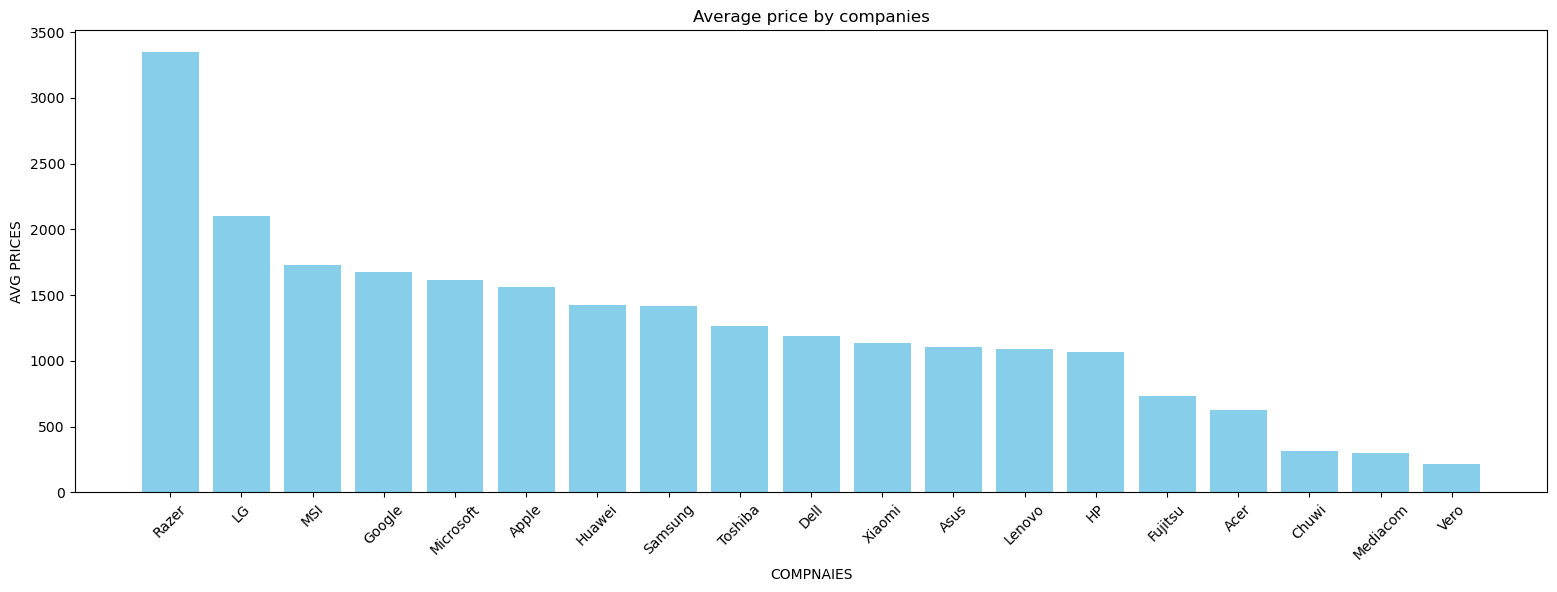

In [28]:
import matplotlib.pyplot as plt 

cp=company_price.index 
pr=company_price.values
plt.figure(figsize=(19,6))
plt.bar(cp,pr,color='skyblue')
plt.title('Average price by companies')
plt.xlabel('COMPNAIES')
plt.ylabel('AVG PRICES')
plt.xticks(rotation=45)  
plt.show()


### 5.2 Average Price per CPU Brand (Horizontal Bar Chart)
* **Goal:** Compare the impact of CPU type on laptop prices. Horizontal layout is used here for better readability of labels.

<Figure size 2000x1500 with 0 Axes>

Text(0.5, 1.0, 'Average laptop price by cpu brand')

<BarContainer object of 40 artists>

Text(0.5, 0, 'cpu_brand')

Text(0, 0.5, 'prices')

(array([   0., 1000., 2000., 3000., 4000., 5000.]),
 [Text(0.0, 0, '0'),
  Text(1000.0, 0, '1000'),
  Text(2000.0, 0, '2000'),
  Text(3000.0, 0, '3000'),
  Text(4000.0, 0, '4000'),
  Text(5000.0, 0, '5000')])

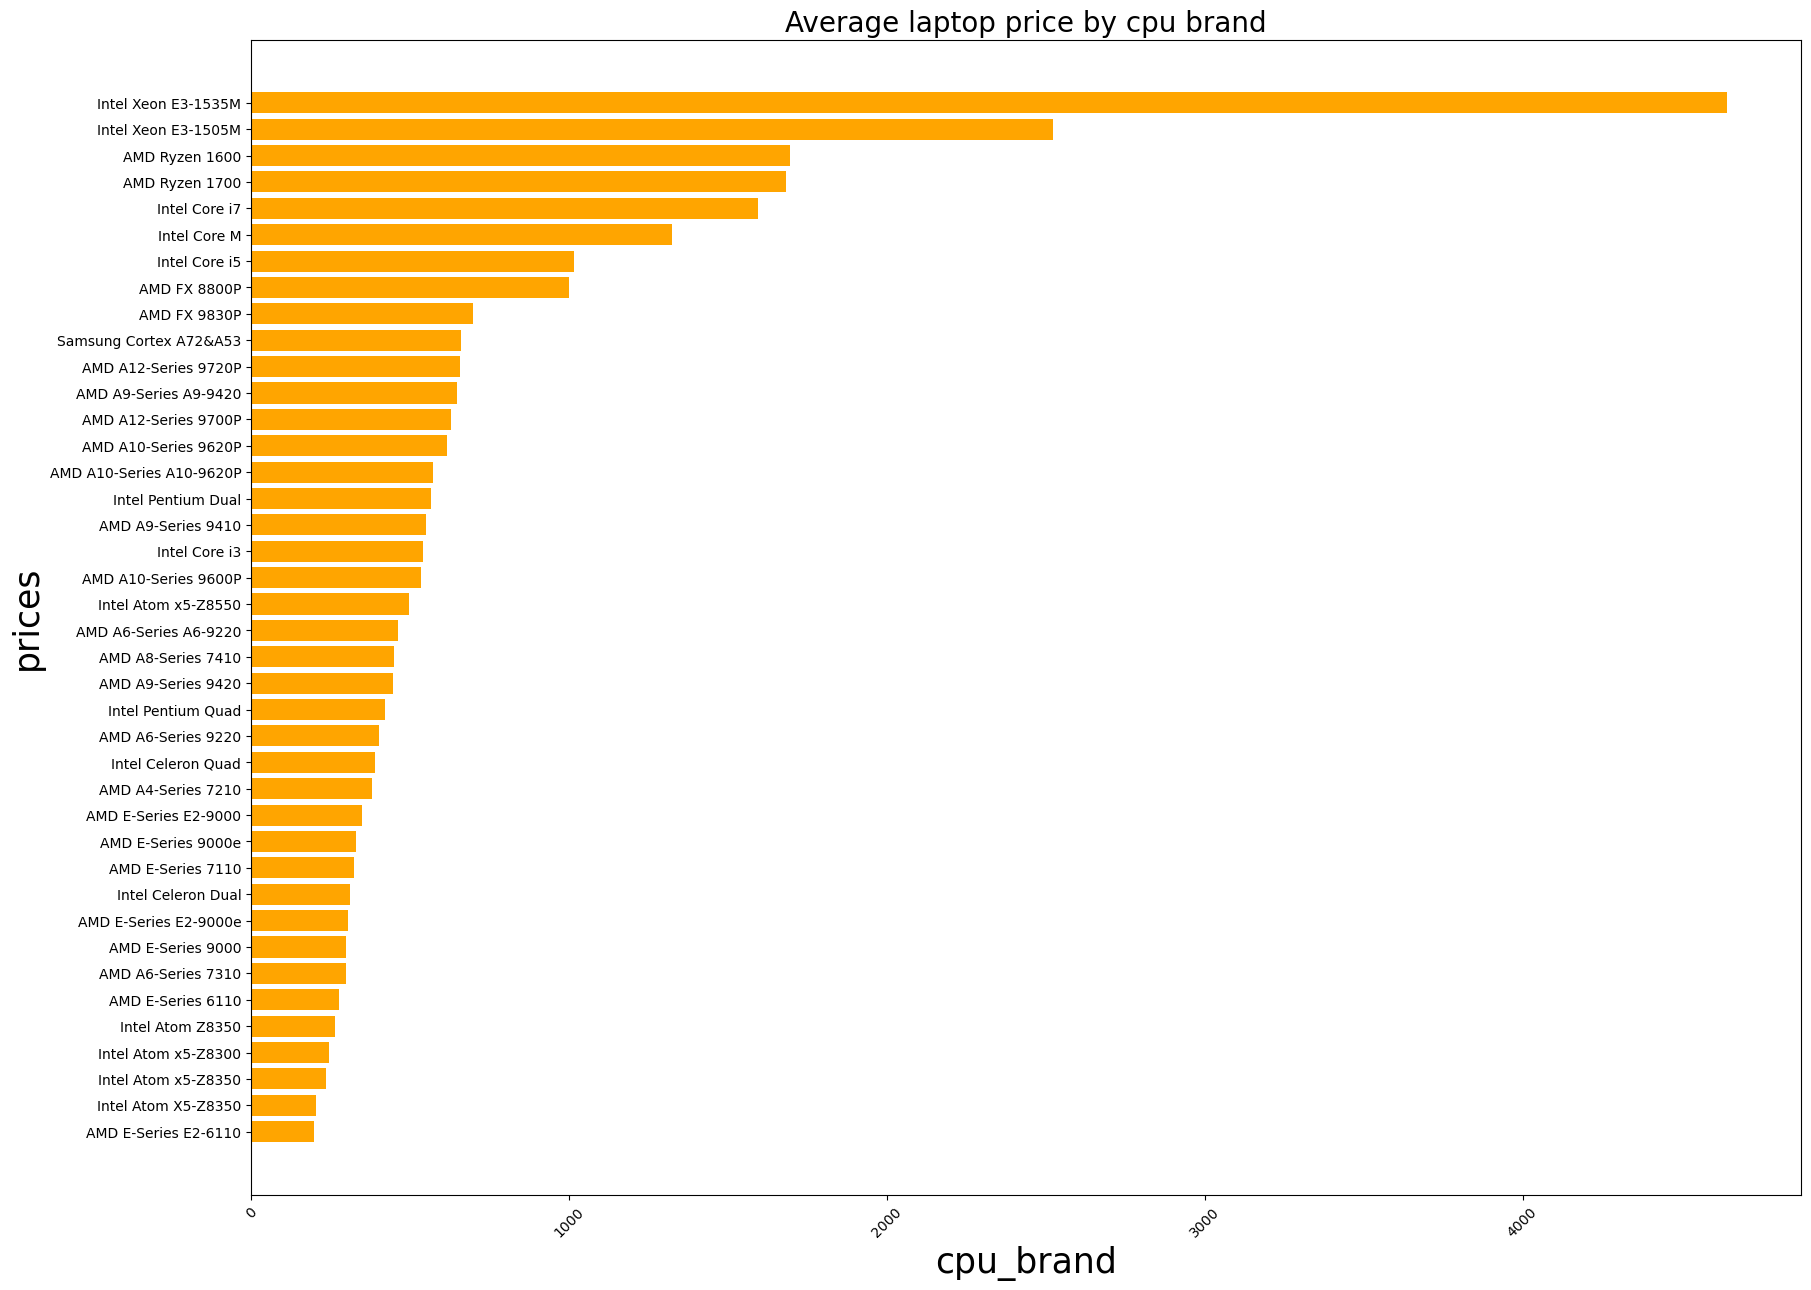

In [27]:
import matplotlib.pyplot as plt 
cpus=cpu_price.index
cpu_prices=cpu_price.values
plt.figure(figsize=(20,15))
plt.title('Average laptop price by cpu brand',fontsize=20)
plt.barh(cpus,cpu_prices,color='orange')  
plt.xlabel('cpu_brand',fontsize=25)
plt.ylabel('prices',fontsize=25)
plt.xticks(rotation=45)
plt.gca().invert_yaxis()  
plt.show()


### 5.3 Average Price by RAM (Bar Chart)
* **Goal:** Show the price jump/correlation based on random-access memory (RAM) size.

<Figure size 1000x1000 with 0 Axes>

Text(0.5, 1.0, 'AVERAGE LAPTOP PRICE BY RAM SIZE')

<BarContainer object of 9 artists>

Text(0.5, 0, 'RAM')

Text(0, 0.5, 'prices')

([0, 1, 2, 3, 4, 5, 6, 7, 8],
 [Text(0, 0, '64GB'),
  Text(1, 0, '32GB'),
  Text(2, 0, '24GB'),
  Text(3, 0, '16GB'),
  Text(4, 0, '12GB'),
  Text(5, 0, '8GB'),
  Text(6, 0, '6GB'),
  Text(7, 0, '4GB'),
  Text(8, 0, '2GB')])

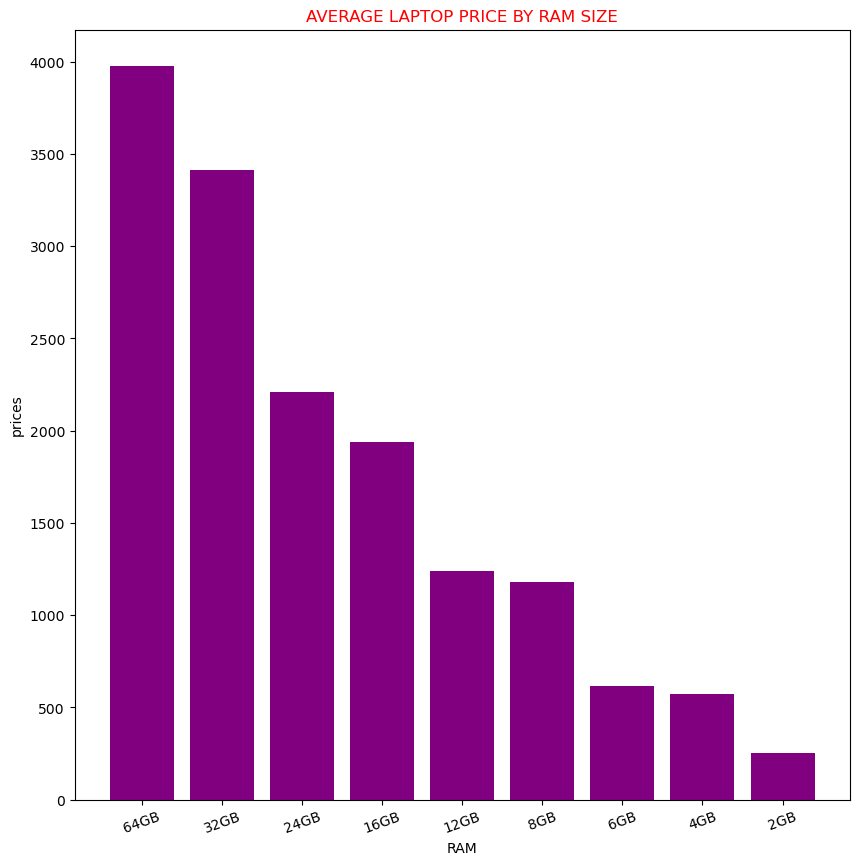

In [26]:
import matplotlib.pyplot as plt
plt.figure(figsize=(10,10))
rm=Ram_price.index
rmp=Ram_price.values
plt.title('AVERAGE LAPTOP PRICE BY RAM SIZE',color='red')
plt.bar(rm,rmp,color='purple')
plt.xlabel('RAM')
plt.ylabel('prices')
plt.xticks(rotation=20)

## 7. Conclusion & Key Insights

Based on the exploratory data analysis (EDA) and visualizations performed on the laptop price dataset (`ltp`), we can draw the following key conclusions:

1. **Manufacturer Impact (Company vs. Price):**
   * Premium brands and manufacturers specializing in high-performance or workstation laptops exhibit significantly higher average prices compared to budget-friendly brands.

2. **Processor Performance (CPU Brand vs. Price):**
   * The choice of CPU plays a massive role in determining the laptop's final price. High-end processors (such as Intel Core i7 and specialized series) drive prices sharply upward, whereas standard everyday processors offer much lower, economical alternatives.

3. **Memory Scaling (RAM vs. Price):**
   * There is a clear and direct positive correlation between RAM capacity and laptop price. Prices increase noticeably and consistently with every step up in RAM size (e.g., from 4GB to 8GB, 16GB, and beyond).

> **💡 Final Takeaway:** A laptop's price is primarily driven by a combination of its brand positioning, processing power (CPU), and memory capacity (RAM), all of which successfully interact to define the distinct market segments we uncovered in this analysis.